# Flood maps in seconds: a SFINCS ensemble on a test valley

**KAI-River · KAI-Hydro · fast flood maps**

**Question.** A storm surge and a two-hour rain burst arrive together on a coastal valley. Where does the water go, how deep does it get, and how much does that answer move when the one parameter nobody measures well, the ground's roughness (Manning's n), is uncertain?

**Why it matters.**
* **Flood warning (KAI-Hydro).** A forecast is only useful if it becomes a map people can act on. SFINCS turns water levels and rain into depth maps in seconds to minutes, fast enough to run many members of a forecast.
* **Urban and rain-on-grid flooding.** SFINCS takes rain directly on every cell, so the same set-up maps flooding from rain in towns and on floodplains, not only from rivers and the sea.
* **Parametric flood triggers.** A trigger read from a flood map (say, the flooded area of a district) carries the model's uncertainty. An ensemble shows how much of the basis risk comes from the model itself.

**Model.** [SFINCS](https://github.com/Deltares/SFINCS) (Super-Fast INundation of CoastS), developed by Deltares and published as open source under GNU GPL-3.0. KAI builds it from that source code (release v2.5.0) in its own container and runs it unchanged; this repository holds no SFINCS code or programs. KAI is not affiliated with Deltares.

**Data.** None from outside: the valley is **synthetic**, generated by the KAI engine (6 km x 3.6 km, 50 m cells), and is not a real place. The model's input files are in `data/model/`; the five members' outputs and the engine's results file are in `results/`.

**Method.** Five runs, identical except that every Manning's n is multiplied by 0.8, 0.9, 1.0, 1.1 or 1.2. The KAI engine reads each run's largest depth per cell, counts the valley floor cells deeper than 0.15 m, and checks the runs (mass balance on a closed basin, valid depths, bounded levels). This notebook reads the same files and reproduces the engine's numbers.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import netCDF4
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#dfe8e8", "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False,
                     "savefig.bbox": "tight", "savefig.facecolor": "white"})
BLUE, ORANGE, GREEN, AMBER, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781"   # KAI chart palette
pathlib.Path("figures").mkdir(exist_ok=True)

MODEL = pathlib.Path("data/model")
MEMBERS = sorted(pathlib.Path("results/members").glob("m*_sfincs_map.nc"))
engine = json.loads(pathlib.Path("results/kai_engine_results.json").read_text())
FACTORS = [m["n_factor"] for m in engine["members"]]
FLOOD_DEPTH = engine["summary"]["flood_depth_m"]          # a cell counts as flooded above 0.15 m
print(engine["engine"]["label"], engine["engine"]["version"], "·", engine["engine"]["source"])
print(len(MEMBERS), "members, Manning's n factors", FACTORS)

SFINCS 2.5.0 · Deltares/SFINCS v2.5.0_Hautacam_release @ 9491715c5b38, built by KAI (docker/sfincs/Dockerfile)
5 members, Manning's n factors [0.8, 0.9, 1.0, 1.1, 1.2]


## 1. The valley
A sea strip with a water-level boundary at the western edge, a beach and a dune ridge, a coastal plain rising inland, and a meandering river channel 150 m wide. Manning's n is 0.02 at sea, 0.03 in the channel and 0.06 on land.

120 x 72 cells of 50 m = 6 km x 3.6 km; ground -5.3 to 5.4 m
Manning's n: [0.02, 0.03, 0.06] (sea, channel, land)


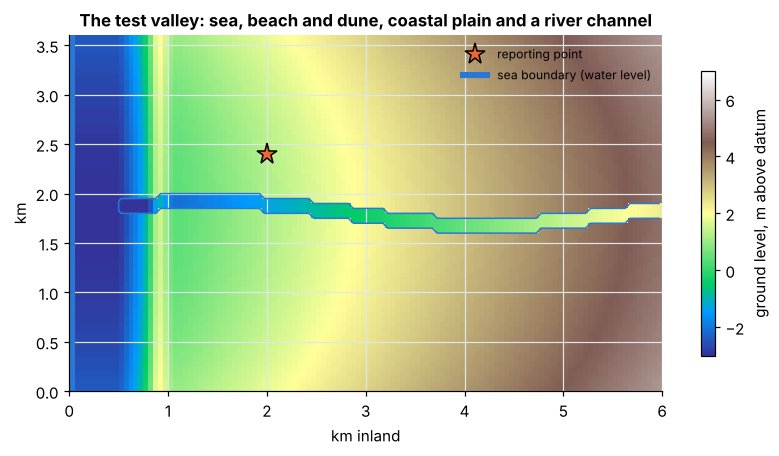

In [2]:
# The model's own input files (SFINCS binary regular-grid format, documented by Deltares)
inp = dict(line.split("=", 1) for line in (MODEL / "sfincs.inp").read_text().splitlines() if "=" in line)
inp = {k.strip(): v.strip() for k, v in inp.items()}
MMAX, NMAX, DX = int(inp["mmax"]), int(inp["nmax"]), float(inp["dx"])
raw = np.fromfile(MODEL / "sfincs.ind", dtype="<i4")
idx = raw[1:1 + raw[0]] - 1                               # 1-based index = (m - 1) * nmax + n, n fastest
m_i, n_i = idx // NMAX, idx % NMAX

def grid(name, dtype="<f4"):
    g = np.full((NMAX, MMAX), np.nan)
    g[n_i, m_i] = np.fromfile(MODEL / name, dtype=dtype)
    return g

zb, manning, msk = grid("sfincs.dep"), grid("sfincs.man"), grid("sfincs.msk", "i1")
x = (np.arange(MMAX) + 0.5) * DX
y = (np.arange(NMAX) + 0.5) * DX
X, Y = np.meshgrid(x, y)
channel = np.isclose(manning, 0.03)                                 # the river channel's own n
floor = (X >= 1000) & ~channel                             # the cells the headline numbers count: behind the beach, outside the channel
site = [float(v) for v in (MODEL / "sfincs.obs").read_text().split()]
print(f"{MMAX} x {NMAX} cells of {DX:g} m = {MMAX * DX / 1000:g} km x {NMAX * DX / 1000:g} km; ground {np.nanmin(zb):.1f} to {np.nanmax(zb):.1f} m")
print("Manning's n:", sorted({round(float(v), 3) for v in np.unique(manning)}), "(sea, channel, land)")

fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.pcolormesh(x / 1000, y / 1000, zb, cmap="terrain", vmin=-3, vmax=7, shading="auto")
ax.contour(x / 1000, y / 1000, channel.astype(float), levels=[0.5], colors=BLUE, linewidths=1)
ax.plot(site[0] / 1000, site[1] / 1000, "*", ms=14, color=ORANGE, mec="k", label="reporting point")
ax.axvline(0.025, color=BLUE, lw=4, label="sea boundary (water level)")
ax.set(xlabel="km inland", ylabel="km", title="The test valley: sea, beach and dune, coastal plain and a river channel", aspect="equal")
fig.colorbar(im, ax=ax, label="ground level, m above datum", shrink=0.8); ax.legend(loc="upper right", fontsize=8)
fig.savefig("figures/valley.png")

## 2. The storm
A 0.6 m tide with a 1.8 m surge peaking at 14 h comes in through the sea boundary. Rain falls on the whole valley at 30 mm/h from 10 h to 12 h, two hours before the surge peak: compound flooding from the sea and from the sky.

peak sea level 1.70 m at 14.2 h; rain 30 mm/h for 2 h = 60 mm


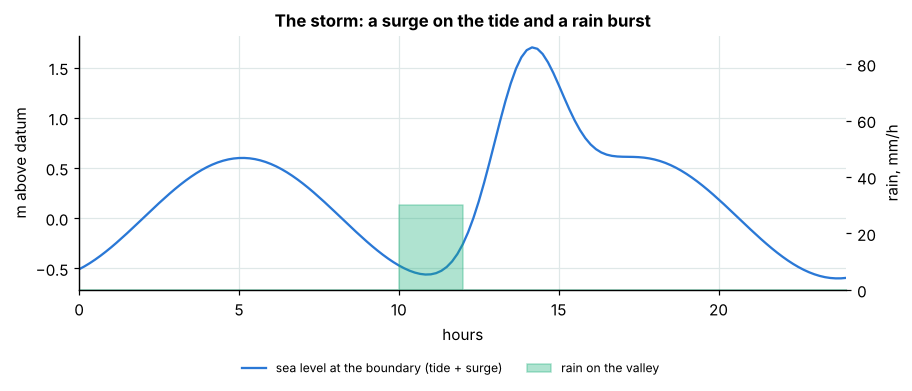

In [3]:
bzs = np.loadtxt(MODEL / "sfincs.bzs")
prcp = np.loadtxt(MODEL / "sfincs.prcp")
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(bzs[:, 0] / 3600, bzs[:, 1], color=BLUE, label="sea level at the boundary (tide + surge)")
ax.set(xlabel="hours", ylabel="m above datum", xlim=(0, 24), title="The storm: a surge on the tide and a rain burst")
ax2 = ax.twinx(); ax2.fill_between(prcp[:, 0] / 3600, prcp[:, 1], step="post", color=GREEN, alpha=0.35, label="rain on the valley")
ax2.set_ylabel("rain, mm/h"); ax2.grid(False); ax2.set_ylim(0, 90)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=8)
fig.savefig("figures/forcing.png")
print(f"peak sea level {bzs[:, 1].max():.2f} m at {bzs[bzs[:, 1].argmax(), 0] / 3600:.1f} h; rain {prcp[:, 1].max():.0f} mm/h for 2 h = {prcp[:, 1].max() * 2:.0f} mm")

## 3. Five members, one roughness each
The table is computed here from the members' map files and compared with the KAI engine's published results; the notebook stops if they differ.

In [4]:
def read_member(path):
    with netCDF4.Dataset(path) as d:
        h = np.array(d["hmax"][-1], dtype=float)
        h = np.where(np.isfinite(h) & (np.abs(h) < 1e30), np.clip(h, 0, None), 0.0)
    return h

hmax = [read_member(p) for p in MEMBERS]
rows = []
for f, h, e in zip(FACTORS, hmax, engine["members"]):
    area = float(((h > FLOOD_DEPTH) & floor).sum() * DX * DX / 1e6)
    rows.append({"n factor": f, "flooded area, km² (this notebook)": round(area, 4), "flooded area, km² (KAI engine)": e["flooded_area_km2"],
                 "largest depth on the floor, m": round(float(h[floor].max()), 3), "inland reach, km": e["inland_reach_km"]})
    assert abs(area - e["flooded_area_km2"]) < 1e-6, (f, area, e["flooded_area_km2"])   # the notebook reproduces the engine
table = pd.DataFrame(rows).set_index("n factor")
table

,"flooded area, km² (this notebook)","flooded area, km² (KAI engine)","largest depth on the floor, m","inland reach, km"
n factor,,,,
0.8,3.4425,3.4425,1.141,2.275
0.9,3.3675,3.3675,1.139,2.225
1.0,3.2875,3.2875,1.137,2.225
1.1,3.2175,3.2175,1.133,2.225
1.2,3.1400,3.1400,1.130,2.225


Smoother ground lets the surge run further inland, so the flooded area grows as n falls. The largest depth on the floor barely moves: it is set by the low ground behind the dune, which fills either way.

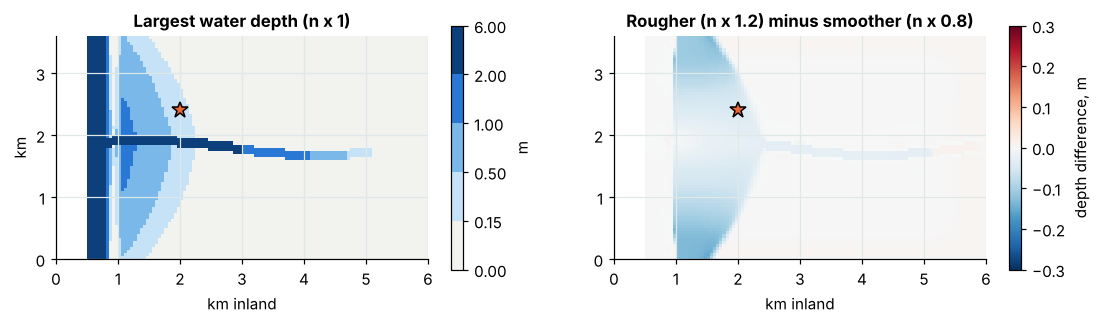

In [5]:
mid = FACTORS.index(1.0)
edges = [0, FLOOD_DEPTH, 0.5, 1.0, 2.0, 6.0]
cmap = ListedColormap(["#f2f2ef", "#c6e2f7", "#7ab8ea", "#2a78d6", "#0d3f7a"]); norm = BoundaryNorm(edges, cmap.N)
land = X >= 500
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
h = np.where(land, hmax[mid], np.nan)
im = axs[0].pcolormesh(x / 1000, y / 1000, h, cmap=cmap, norm=norm, shading="auto")
axs[0].set(title="Largest water depth (n x 1)", xlabel="km inland", ylabel="km", aspect="equal")
fig.colorbar(im, ax=axs[0], label="m", shrink=0.8, ticks=edges)
d = np.where(land, hmax[-1] - hmax[0], np.nan)
im2 = axs[1].pcolormesh(x / 1000, y / 1000, d, cmap="RdBu_r", vmin=-0.3, vmax=0.3, shading="auto")
axs[1].set(title=f"Rougher (n x {FACTORS[-1]:g}) minus smoother (n x {FACTORS[0]:g})", xlabel="km inland", aspect="equal")
fig.colorbar(im2, ax=axs[1], label="depth difference, m", shrink=0.8)
for a in axs: a.plot(site[0] / 1000, site[1] / 1000, "*", ms=11, color=ORANGE, mec="k")
fig.savefig("figures/depth_maps.png")

## 4. Water level at one point
The reporting point sits on the floodplain 1 km behind the dune. Its peak comes with the surge, after the rain has already filled the low ground.

peak level at the point by n factor: {0.8: np.float64(1.566), 0.9: np.float64(1.557), 1.0: np.float64(1.548), 1.1: np.float64(1.537), 1.2: np.float64(1.524)}
site_peak_level_m {'p10': 1.52921, 'p50': 1.54752, 'p90': 1.56268, 'min': 1.52429, 'max': 1.56635}
flooded_area_km2 {'p10': 3.171, 'p50': 3.2875, 'p90': 3.4125, 'min': 3.14, 'max': 3.4425}


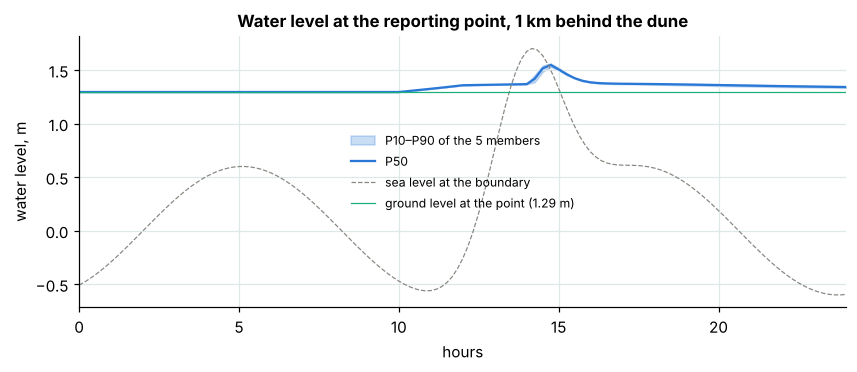

In [6]:
series = []
for p in sorted(pathlib.Path("results/members").glob("m*_sfincs_his.nc")):
    with netCDF4.Dataset(p) as d:
        t = np.array(d["time"][:], dtype=float) / 3600
        zs = np.array(d["point_zs"][:, 0], dtype=float)
        bed = float(np.array(d["point_zb"][:])[0])
        series.append(np.where(zs > -100, zs, bed))           # dry times: SFINCS writes a fill value; show the ground level
s = np.vstack(series)
p10, p50, p90 = np.percentile(s, [10, 50, 90], axis=0)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.fill_between(t, p10, p90, color=BLUE, alpha=0.25, label="P10–P90 of the 5 members")
ax.plot(t, p50, color=BLUE, label="P50")
ax.plot(bzs[:, 0] / 3600, bzs[:, 1], color=GREY, lw=0.8, ls="--", label="sea level at the boundary")
ax.axhline(bed, color=GREEN, lw=0.8, label=f"ground level at the point ({bed:.2f} m)")
ax.set(xlabel="hours", ylabel="water level, m", xlim=(0, 24), title="Water level at the reporting point, 1 km behind the dune")
ax.legend(fontsize=8); fig.savefig("figures/site_level.png")
peaks = s.max(axis=1)
print("peak level at the point by n factor:", dict(zip(FACTORS, np.round(peaks, 3))))
for k in ("site_peak_level_m", "flooded_area_km2"):
    print(k, engine["summary"][k])

## 5. What this means for a parametric trigger
Suppose a policy paid when the flooded area of the valley floor passed a set level. With everything else known exactly, roughness alone moves the index by several percent, enough to decide whether a trigger near the middle pays. In practice that is a reason to calibrate n on a past flood, or to set the trigger with the band in view, before a single payout depends on it.

In [7]:
# A parametric flood index read from the maps: the flooded area of the valley floor. How often would a trigger
# at a given area pay, if the only thing we did not know were the roughness?
areas = table["flooded area, km² (this notebook)"].to_numpy()
triggers = np.round(np.arange(3.10, 3.50, 0.05), 2)
pay = pd.DataFrame({"trigger, km²": triggers, "members that pay (of 5)": [int((areas >= t).sum()) for t in triggers]})
spread = (areas.max() - areas.min()) / np.median(areas) * 100
print(f"flooded area across the members: {areas.min():.2f}–{areas.max():.2f} km², a spread of {spread:.0f} % from roughness alone")
pay.set_index("trigger, km²").T

flooded area across the members: 3.14–3.44 km², a spread of 9 % from roughness alone


"trigger, km²",3.10,3.15,3.20,3.25,3.30,3.35,3.40,3.45
members that pay (of 5),5,4,4,3,2,2,1,0


## 6. The engine's checks

In [8]:
pd.DataFrame([{"check": c["name"], "ok": c["ok"], "value": c["value"], "what it tests": c["note"]} for c in engine["checks"]]).set_index("check")

,ok,value,what it tests
check,,,
sfincs_finished,True,True,SFINCS wrote its map output for every member a...
depths_valid,True,0,cells with a missing or negative maximum depth
levels_bounded,True,0,flooded cells whose peak level is above both t...
mass_balance,True,-0.1812,closed-basin run: stored volume gain against t...
ensemble_effect,True,0.3446,the roughness members differ in site peak leve...


## Limits
* **Synthetic.** The valley, the storm and the roughness values are invented to test the chain; nothing here describes a real place or a real flood.
* **One storm, one uncertain parameter.** Only Manning's n varies. Real uncertainty also comes from the forcing (the forecast surge and rain), the terrain and, in towns, buildings and drains.
* **No infiltration** (`qinf = 0`): all rain becomes runoff, which is the cautious choice for a test.
* **50 m cells.** Urban flooding needs finer terrain, buildings and drainage; for real sites KAI builds SFINCS models from a terrain model with HydroMT-SFINCS, which is the next step.

## Run it yourself
Build SFINCS from [its source](https://github.com/Deltares/SFINCS) following Deltares' instructions, then run it in a copy of `data/model/` (the n x 1 member). For another member, multiply the float32 values in `sfincs.man` by its factor. The KAI engine that prepares and checks the runs is not part of this repository.

*Simulated results on a synthetic test case. © 2026 KAI Water & Energy; data and figures CC BY 4.0, code MIT.*